# Imports

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glhmm import glhmm, preproc, utils, graphics
import mne
from pathlib import Path

from scipy import signal
from scipy.ndimage import uniform_filter1d

import helpers.utils_glhmm as utils
# reload utils
import importlib
importlib.reload(utils)

from IPython.display import clear_output


In [14]:
N_STATES = 5 # Number of hidden states in the GLHMM
NAP_DURATION_MIN = 30 # Keep the first N minutes of each subject's EXPERIMENT_STAGE
EXPERIMENT_STAGE = 'Nap1'
COVTYPE = 'full' # 'full' or 'diag' or 'sharedfull'

FULL_STAGE = True # If False, only the first NAP_DURATION_MIN minutes of each subject's EXPERIMENT_STAGE are kept
CROP_END_PROBE = True  # end the window at the onset of the session's last probe (task paused for the questions, ~2-2.5 min)
PREPROC = True 
SLEEP_STAGES = True # Train on slow band-power envelopes  instead of the raw EEG signal
VERBOSE = False
SHOW_BAD_SPANS = True  # show the spans annotated as bad under the hidden states (sleep stage plot)
REMOVE_BAD_SPANS = False  # TODO: remove the spans annotated as bad in the preprocessing

GAMM_DIR = Path('C:/Users/eva/Documents/Master/ICM/Ilo/Data/GAMM')
out_dir = Path('C:/Users/eva/Documents/Master/ICM/Ilo/Outputs/GLHMM')

BANDS = {'delta': (0.5, 4), 'theta': (4, 8), 'alpha': (8, 12), 'sigma': (12, 16), 'beta': (16, 30)}
# Channels are pooled by region
REGIONS = {'Frontal': ['Fp', 'AF', 'F'], 'Central': ['FC', 'C', 'CP'], 'Temporal': ['FT', 'T', 'TP'],
           'Parietal': ['P'], 'Occipital': ['PO', 'O']}
ENV_SMOOTH_S = 2  # moving-average window applied to the envelopes (s)
FS_ENV = 4        # Hz: sampling rate of the envelopes given to the HMM


# Add physiological features
EMG_BAND = (20, 35)  # Hz: above ECG/movement leakage, steep cut below the 50 Hz line noise left at the 100 Hz Nyquist
# EOG features: name -> (band in Hz, smoothing in s)
EOG_FEATURES = {
    'EOG slow': ((0.1, 0.5), 10),  # slow eye movements (one sweep every 2-10 s, so 10 s smoothing), below the 0.3-40 Hz EEG band
    'EOG fast': ((0.5, 5), ENV_SMOOTH_S),  # blinks and saccades; in sleep it also picks up frontal delta and K-complexes
}
ECG = True  # add the ECG features to Y_prep; the sessions without a usable ECG are then dropped (TT004, TT005, TT008 in Nap1)
# ECG features, from the R-peaks of the 500 Hz BrainVision ECG (the .fif is at 100 Hz: 10 ms beat timing, too coarse for RMSSD)
ECG_FEATURES = ['HR', 'RMSSD']  # heart rate (bpm) and RMSSD, the beat-to-beat variability driven by vagal tone (ms)
HR_SMOOTH_S = 4        # s: averages out the heart-rate oscillation that follows breathing (~4 s per breath)
HRV_WIN_S = 30         # s: window of the RMSSD, ~30 beats are needed for a stable value
ECG_MIN_RR_KEPT = 0.8  # a session where fewer RR intervals pass the cleaning has no usable ECG

# Add behavioural features (time-production task)
BEHAV = True  # add the behavioural features to Y_prep; the sessions with fewer than 2 IRT intervals are then dropped
BEHAV_FEATURES = ['IRT', 'press rate']  # log(IRT / target) between presses, and presses (Response + Reset) per minute
PRESS_RATE_SIGMA_S = 30  # s: SD of the Gaussian kernel of the press rate, about one target interval
MIN_IRT_S = 5  # s: shorter IRT intervals are double presses or corrections, not a time production (left out of the IRT)


# Load and prepare data
Each `EEG/<subject>_preproc_raw.fif` is one continuous ~3h recording, already preprocessed by `preprocessing.ipynb` / `helpers/preprocessing.py` (50 Hz notch, band-pass, 100 Hz, bad channels interpolated, average reference, bad time spans annotated). No preprocessing is done here: the first `NAP_DURATION_MIN` minutes of Nap2 are cropped. The spans annotated as bad are kept, so a session here = the whole Nap2 window of one subject (`bad_s` in `sessions_meta` gives how much of it is annotated as bad).

In [15]:
data_dir = Path('C:/Users/eva/Documents/Master/ICM/Ilo/Data/EEG')
fif_files = utils.find_files(data_dir, '*_preprocessed.fif', VERBOSE)

# Which raw 'Session N' is Nap2 differs between subjects (e.g. TT004 -> Session 7), so take the mapping from the GAMM tables
session_map = pd.read_csv(GAMM_DIR / '09_presses_staged.csv')[['subname', 'session', 'session_raw']].drop_duplicates()
stages_df = pd.read_csv(GAMM_DIR / '08_sleep_stages.csv')

Y, indices, sessions_meta, fs, ch_names = utils.load_eeg_data(fif_files, EXPERIMENT_STAGE, session_map, stages_df, FULL_STAGE, CROP_END_PROBE, NAP_DURATION_MIN, VERBOSE)

# Hypnogram: one row per scored 30-s epoch (08_sleep_stages only has the epochs that contain an event)
EPOCH_S = 30
sleep_stages = utils.load_sleep_stages(pd.read_csv(GAMM_DIR / '12_hypnogram_epochs.csv'))  # subject -> {epoch_idx: stage}

# remove cell output
if not VERBOSE: clear_output(wait=False)


print(f'Y shape: {Y.shape}  (n_samples_total x n_channels)')
print(f'indices shape: {indices.shape}  (n_sessions x 2, {sessions_meta.subject.nunique()} subjects)')
print(f'{len(ch_names)} EEG channels, fs = {fs} Hz')
print(f'Y size in memory: {Y.nbytes / 1e9:.2f} GB')
sessions_meta

Y shape: (1829003, 63)  (n_samples_total x n_channels)
indices shape: (15, 2)  (n_sessions x 2, 15 subjects)
63 EEG channels, fs = 100 Hz
Y size in memory: 0.46 GB


,subject,file,start,end,crop_start_s,crop_end_s,duration_min,bad_s,bad_spans
0,TT001,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,0,172489,3033.152,4758.038,28.7,0.0,[]
1,TT002,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,172489,267237,1864.574,2812.054,15.8,0.0,[]
2,TT004,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,267237,398122,2633.054,3941.896,21.8,0.0,[]
3,TT005,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,398122,562587,3528.884,5173.526,27.4,2.1,"[(1231.9700979999998, 1234.0701956562498)]"
4,TT006,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,562587,629954,2091.290,2764.962,11.2,5.1,"[(139.00003900000002, 144.14994134375002)]"
5,TT007,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,629954,707069,2312.452,3083.598,12.9,0.0,[]
6,TT008,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,707069,887345,3117.180,4919.940,30.0,0.0,[]
7,TT009,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,887345,1000065,2661.852,3789.046,18.8,2.8,"[(496.44003900000007, 499.19003900000007)]"
8,TT011,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,1000065,1180351,2585.444,4388.300,30.0,0.0,[]
9,TT012,C:\Users\eva\Documents\Master\ICM\Ilo\Data\EEG...,1180351,1224128,2676.804,3114.566,7.3,0.0,[]


In [16]:
if SLEEP_STAGES:
    Y_prep = [utils.band_power_envelopes(Y[a:b], fs, ch_names, REGIONS, BANDS, FS_ENV, ENV_SMOOTH_S) for a, b in indices]
    ends_prep = np.cumsum([x.shape[0] for x in Y_prep])
    indices_prep = np.column_stack([ends_prep - [x.shape[0] for x in Y_prep], ends_prep])
    Y_prep = np.vstack(Y_prep)
    # Standardise within each subject, over all its sessions: differences between two sessions of a subject are kept
    for sub in sessions_meta.subject.unique():
        rows = np.concatenate([np.arange(a, b) for a, b in indices_prep[(sessions_meta.subject == sub).values]])
        Y_prep[rows] = (Y_prep[rows] - Y_prep[rows].mean(axis=0)) / Y_prep[rows].std(axis=0)
    fs_prep = FS_ENV
    feature_names = [f'{r} {b}' for b in BANDS for r in REGIONS]
elif PREPROC:
    Y_prep, indices_prep, prep_log = preproc.preprocess_data(data=Y, indices=indices, fs=fs,
        dampen_extreme_peaks=5,
        standardise=True)
    fs_prep, feature_names = fs, ch_names
else:
    Y_prep, indices_prep, fs_prep, feature_names = Y, indices, fs, ch_names


assert np.isfinite(Y_prep).all(), 'NaN/inf in Y_prep'
MODEL_TAG = 'bandpower' if SLEEP_STAGES else 'raw'  # keeps the two kinds of model apart on disk

print(f'Y_prep shape: {Y_prep.shape}  ({fs_prep} Hz, {len(feature_names)} features)')
print(f'indices_prep shape: {indices_prep.shape}')

# Save for reuse in the modelling cells below

np.save(out_dir / f'Y_prep_full_eeg_{MODEL_TAG}.npy', Y_prep)
np.save(out_dir / f'indices_prep_full_eeg_{MODEL_TAG}.npy', indices_prep)
sessions_meta.to_csv(out_dir / 'sessions_meta_full_eeg.csv', index=False)
with open(out_dir / 'channel_names_full_eeg.txt', 'w') as fh:
    fh.write('\n'.join(ch_names))

print(f'Saved Y_prep_full_eeg_{MODEL_TAG}.npy, indices_prep_full_eeg_{MODEL_TAG}.npy, sessions_meta_full_eeg.csv, channel_names_full_eeg.txt to {out_dir}')

Y_prep shape: (73161, 25)  (4 Hz, 25 features)
indices_prep shape: (15, 2)
Saved Y_prep_full_eeg_bandpower.npy, indices_prep_full_eeg_bandpower.npy, sessions_meta_full_eeg.csv, channel_names_full_eeg.txt to C:\Users\eva\Documents\Master\ICM\Ilo\Outputs\GLHMM


## Include physiological data to Y
### EMG signal
Load EMG signal:


In [17]:
# Load EMG signal if it exists
emg_raw, _ = utils.load_physiological_data(sessions_meta, 'EMG', fs)

# Create an EMG-derived feature
emg_feat = {s: utils.emg_envelope(x, fs, EMG_BAND, FS_ENV, ENV_SMOOTH_S) for s, x in emg_raw.items()}
for s, e in emg_feat.items():
    assert len(e) == indices_prep[s, 1] - indices_prep[s, 0], f'{sessions_meta.subject[s]}: EMG and EEG features have different lengths'

EMG found for 13 / 15 sessions


Verify Gaussianity:

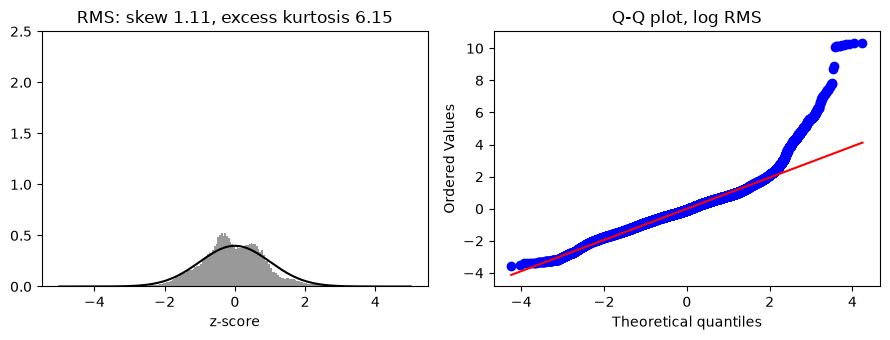

Mean z-scored EMG per subject and sleep stage:
stage       1     2     W
subject                  
TT004   -0.05 -0.01  0.02
TT005   -0.36 -0.69  0.11
TT006    0.08   NaN -0.01
TT007   -1.59 -2.00  0.31
TT008   -1.44   NaN  0.05
TT009     NaN   NaN  0.00
TT011     NaN   NaN -0.00
TT012     NaN -1.61  0.38
TT013   -0.16 -0.69  0.06
TT014     NaN  0.95 -0.57
TT015     NaN   NaN  0.00
TT017   -0.21 -0.54  0.33
TT018     NaN   NaN  0.00


In [ ]:
utils.verify_gaussianity(emg_feat, 'EMG log RMS')  # check that the EMG is Gaussian within each session, and per sleep stage

# Per sleep stage: the EMG should drop from W to N1/N2 (muscle tone)
print('\nMean z-scored EMG per subject and sleep stage:')
print(utils.mean_by_stage(emg_feat, 'EMG', sessions_meta, sleep_stages, FS_ENV, EPOCH_S))

The data distribution seems sufficiently Gaussian, the log brings the EMG from strongly non-Gaussian into the same range as the EEG features.

Q-Q plot: the data stays close to the red line between -3 and ~2, then the points bend upward --> heavy right tail, where points have much higher EMG tnan a Gaussian would predict. These might be muscle bursts from movements, swallowing and maybe the presses.

Add the EMG feature to the Y matrix:


In [ ]:
Y_prep, indices_prep, indices, sessions_meta, feature_names = utils.add_feat_to_Y(
    Y_prep, indices_prep, indices, sessions_meta, feature_names, emg_feat, ['EMG'], 'no EMG channel')
MODEL_TAG += '_emg'

dropping ['TT001', 'TT002'] (no EMG channel)
Y_prep shape: (69500, 26)  (4 Hz, 26 features)
indices_prep shape: (13, 2)


### EOG signal

In [ ]:
eog_raw, _ = utils.load_physiological_data(sessions_meta, 'IO', fs)  # IO: the EOG channel

C:\Users\eva\AppData\Local\Temp\ipykernel_16616\4094926285.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT004_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\4094926285.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT005_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\4094926285.py:4: RuntimeWarning: This filename

EOG found for 13 / 13 sessions


Create an EOG-derived feature:


In [ ]:
def eog_envelope(x, fs, band, smooth_s):
    """(n_times,) EOG -> (n_times_env,) log amplitude envelope in band, on the same grid as band_power_envelopes."""
    sos = signal.butter(2, band, 'bandpass', output='sos', fs=fs)
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x)))
    step = int(fs / FS_ENV)
    return np.log(uniform_filter1d(env, int(smooth_s * fs), mode='nearest')[step // 2::step])


# session index -> (n_times_env, n_eog_features), one column per entry of EOG_FEATURES
eog_feat = {s: np.column_stack([eog_envelope(x, fs, band, smooth_s) for band, smooth_s in EOG_FEATURES.values()])
            for s, x in eog_raw.items()}
for s, e in eog_feat.items():
    assert len(e) == indices_prep[s, 1] - indices_prep[s, 0], f'{sessions_meta.subject[s]}: EOG and EEG features have different lengths'

Verify Gaussianity:


correlation between the EOG features:
          EOG slow  EOG fast
EOG slow      1.00      0.43
EOG fast      0.43      1.00


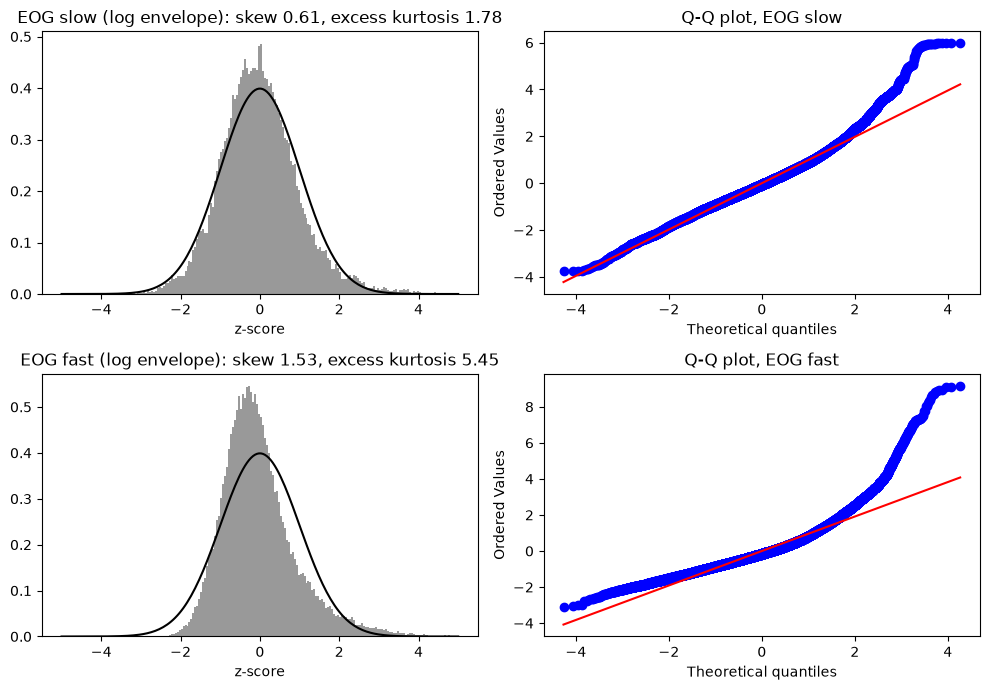


Mean z-scored EOG per subject and sleep stage:
        EOG fast             EOG slow            
stage          1     2     W        1     2     W
subject                                          
TT004      -0.37  0.04  0.06    -0.09 -0.66  0.44
TT005      -0.06  0.34 -0.03     0.01 -0.11  0.01
TT006      -0.28   NaN  0.02    -0.59   NaN  0.05
TT007       0.75  1.07 -0.14    -0.40 -0.76  0.09
TT008      -0.97   NaN  0.03     0.56   NaN -0.02
TT009        NaN   NaN -0.00      NaN   NaN -0.00
TT011        NaN   NaN -0.00      NaN   NaN  0.00
TT012        NaN  0.41 -0.08      NaN -1.04  0.20
TT013       0.03  0.32 -0.02    -0.11 -0.71  0.05
TT014        NaN -0.22  0.10      NaN -0.44  0.21
TT015        NaN   NaN -0.00      NaN   NaN -0.00
TT017      -0.67 -0.49  0.33    -0.18 -0.83  0.33
TT018        NaN   NaN  0.00      NaN   NaN  0.00


In [ ]:
utils.verify_gaussianity(eog_feat, list(EOG_FEATURES))

# Per sleep stage: eye movements should become rarer from W to N2
print('\nMean z-scored EOG per subject and sleep stage:')
print(utils.mean_by_stage(eog_feat, list(EOG_FEATURES), sessions_meta, sleep_stages, FS_ENV, EPOCH_S))

The data distribution seems sufficiently Gaussian, the log brings the EMG from strongly non-Gaussian into the same range as the EEG features.

Q-Q plot: the data stays close to the red line between -3 and ~2, then the points bend upward --> heavy right tail, where points have much higher EMG tnan a Gaussian would predict. These might be muscle bursts from movements, swallowing and maybe the presses.

Add the EMG feature to the Y matrix:

In [ ]:
Y_prep, indices_prep, indices, sessions_meta, feature_names = utils.add_feat_to_Y(
    Y_prep, indices_prep, indices, sessions_meta, feature_names, eog_feat, EOG_FEATURES, 'no EOG channel')
MODEL_TAG += '_eog'

Y_prep shape: (69500, 28)  (4 Hz, 28 features)
indices_prep shape: (13, 2)


### ECG signal

In [ ]:
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import median_filter


def r_peaks(x, fs):
    """(n_times,) ECG in microvolts -> times (s) of the R-peaks, with MNE's adaptive QRS detector."""
    info = mne.create_info(['ECG'], fs, 'ecg')
    ev = mne.preprocessing.find_ecg_events(mne.io.RawArray(x[None] * 1e-6, info, verbose=False), ch_name='ECG', verbose=False)[0]
    return ev[:, 0] / fs


def clean_rr(t):
    """Beat times -> (end time, length) of the RR intervals kept, and the fraction kept. An interval is kept between
    30 and 180 bpm and within 20 % of the median of the 11 around it: a missed or extra beat gives one far from its neighbours."""
    rr, tm = np.diff(t), t[1:]
    med = median_filter(rr, size=11, mode='nearest')
    ok = (rr > 0.33) & (rr < 2.0) & (np.abs(rr - med) < 0.2 * med)
    return tm[ok], rr[ok], ok.mean()


def ecg_features(t_beats, n_env):
    """R-peak times (s from the window start) -> (n_env, len(ECG_FEATURES)) log HR / log RMSSD on the envelope grid."""
    tm, rr, _ = clean_rr(t_beats)
    te = (np.arange(n_env) + 0.5) / FS_ENV  # centre of each envelope sample, s from the window start
    feats = {}
    # Heart rate: one value per beat, interpolated onto the grid (held constant before the first / after the last beat)
    hr = PchipInterpolator(tm, 60 / rr, extrapolate=False)(te)
    hr = np.where(te < tm[0], 60 / rr[0], np.where(te > tm[-1], 60 / rr[-1], hr))
    feats['HR'] = np.log(uniform_filter1d(hr, int(HR_SMOOTH_S * FS_ENV), mode='nearest'))
    # RMSSD over a centred HRV_WIN_S window, only from differences between two consecutive kept RR intervals
    consec = np.isclose(np.diff(tm), rr[1:], atol=1e-3)  # the next kept interval starts where this one ends
    td, d2 = tm[1:][consec], np.diff(rr)[consec] ** 2
    csum = np.r_[0, np.cumsum(d2)]
    lo, hi = np.searchsorted(td, te - HRV_WIN_S / 2), np.searchsorted(td, te + HRV_WIN_S / 2)
    ms = np.where(hi - lo >= 10, (csum[hi] - csum[lo]) / np.maximum(hi - lo, 1), np.nan)
    ms = pd.Series(ms).ffill().bfill().values  # windows with < 10 differences (edges, noisy spans) take the closest value
    feats['RMSSD'] = np.log(np.sqrt(ms) * 1000)
    return np.column_stack([feats[k] for k in ECG_FEATURES])


# The .fif and the BrainVision recording share the same time axis, so the EEG window of each session is cropped directly
ecg_raw, fs_ecg = utils.load_physiological_data(sessions_meta, 'ECG', fs, vhdr_dir=data_dir)
ecg_feat = {}  # session index (row of sessions_meta) -> (n_times_env, len(ECG_FEATURES)), only for the usable ECGs
for s, x in ecg_raw.items():
    row = sessions_meta.loc[s]
    t = r_peaks(x, fs_ecg)
    kept = clean_rr(t)[2] if len(t) > 2 else 0.0
    if len(t) < len(x) / fs_ecg / 2 or kept < ECG_MIN_RR_KEPT:  # < 30 bpm detected, or too many beats missed / extra
        print(f"  {row.subject}: unusable ECG ({len(t)} beats, {kept:.0%} of RR intervals kept)")
        continue
    ecg_feat[s] = ecg_features(t, indices_prep[s, 1] - indices_prep[s, 0])
    print(f"  {row.subject}: {len(t)} beats, {kept:.0%} of RR intervals kept, median HR {60 / np.median(np.diff(t)):.0f} bpm")

print(f'usable ECG for {len(ecg_feat)} / {len(sessions_meta)} sessions')

C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: No coordinate information found for channels ['IO', 'Left Index+Middle', 'Left Ring+Pinky', 'Left Thumb', 'Right Ring+Pinky', 'Right Thumb', 'EMG', 'ECG']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Online software filter detected. Using software filter settings and ignoring hardware values
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Channels contain different highpass filters. Lowest (weakest) filter setting (0.00 Hz) will be stored.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Tem

  TT004: unusable ECG (0 beats, 0% of RR intervals kept)


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: No coordinate information found for channels ['IO', 'Left Index+Middle', 'Left Ring+Pinky', 'Left Thumb', 'Right Ring+Pinky', 'Right Thumb', 'EMG', 'ECG']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Online software filter detected. Using software filter settings and ignoring hardware values
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Channels contain different highpass filters. Lowest (weakest) filter setting (0.00 Hz) will be stored.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Tem

  TT005: unusable ECG (41 beats, 0% of RR intervals kept)


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: No coordinate information found for channels ['IO', 'Left Index+Middle', 'Left Ring+Pinky', 'Left Thumb', 'Right Ring+Pinky', 'Right Thumb', 'EMG', 'ECG']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Online software filter detected. Using software filter settings and ignoring hardware values
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Channels contain different highpass filters. Lowest (weakest) filter setting (0.00 Hz) will be stored.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Tem

  TT006: 983 beats, 93% of RR intervals kept, median HR 75 bpm


... (16 outputs left out)

C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: No coordinate information found for channels ['IO', 'Left Index+Middle', 'Left Ring+Pinky', 'Left Thumb', 'Right Ring+Pinky', 'Right Thumb', 'EMG', 'ECG']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Online software filter detected. Using software filter settings and ignoring hardware values
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Channels contain different highpass filters. Lowest (weakest) filter setting (0.00 Hz) will be stored.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Tem

  TT017: 397 beats, 93% of RR intervals kept, median HR 60 bpm


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: No coordinate information found for channels ['IO', 'Left Index+Middle', 'Left Ring+Pinky', 'Left Thumb', 'Right Ring+Pinky', 'Right Thumb', 'EMG', 'ECG']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Online software filter detected. Using software filter settings and ignoring hardware values
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3826196644.py:44: RuntimeWarning: Channels contain different highpass filters. Lowest (weakest) filter setting (0.00 Hz) will be stored.
  raw = mne.io.read_raw_brainvision(data_dir / f'{row.subject}.vhdr', preload=False, verbose=0)
C:\Users\eva\AppData\Local\Tem

  TT018: 1796 beats, 91% of RR intervals kept, median HR 53 bpm
usable ECG for 10 / 13 sessions


Verify Gaussianity:

correlation between the ECG features:
         HR  RMSSD
HR     1.00  -0.17
RMSSD -0.17   1.00


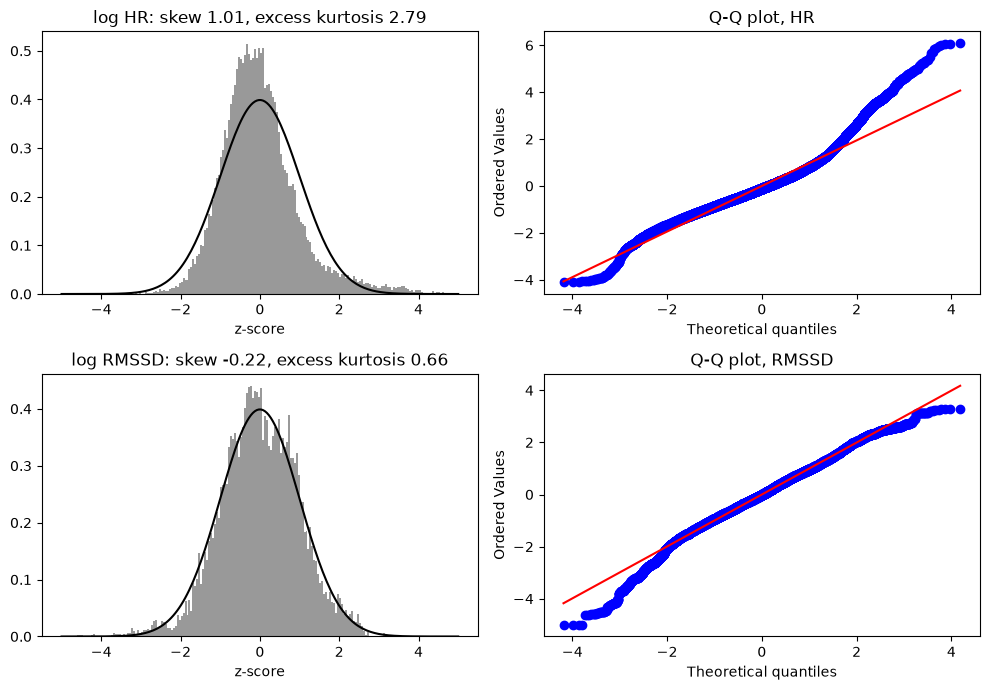


Mean z-scored ECG features per subject and sleep stage:
           HR             RMSSD            
stage       1     2     W     1     2     W
subject                                    
TT006   -0.97   NaN  0.08  1.70   NaN -0.13
TT007   -1.09 -0.82  0.15 -0.49 -0.41  0.07
TT009     NaN   NaN  0.00   NaN   NaN -0.00
TT011     NaN   NaN -0.00   NaN   NaN -0.00
TT012     NaN -1.09  0.21   NaN -0.14  0.03
TT013   -0.68 -1.23  0.15  0.54  0.65 -0.10
TT014     NaN -0.74  0.35   NaN  0.97 -0.46
TT015     NaN   NaN -0.00   NaN   NaN -0.00
TT017   -0.88 -0.50  0.38  0.36  0.41 -0.23
TT018     NaN   NaN  0.00   NaN   NaN  0.00


In [ ]:
utils.verify_gaussianity(ecg_feat, [f'log {name}' for name in ECG_FEATURES])

# Per sleep stage: the heart rate should drop and the RMSSD (vagal tone) rise from W to N2
print('\nMean z-scored ECG features per subject and sleep stage:')
print(utils.mean_by_stage(ecg_feat, ECG_FEATURES, sessions_meta, sleep_stages, FS_ENV, EPOCH_S))

Add the ECG features to the Y matrix:

In [ ]:
if not ECG:
    print('ECG = False: the ECG features are not added to Y_prep (ecg_feat is kept for analyses after training)')
else:
    Y_prep, indices_prep, indices, sessions_meta, feature_names = utils.add_feat_to_Y(
        Y_prep, indices_prep, indices, sessions_meta, feature_names, ecg_feat, ECG_FEATURES, 'no usable ECG')
    MODEL_TAG += '_ecg'

dropping ['TT004', 'TT005', 'TT008'] (no usable ECG)
Y_prep shape: (48743, 30)  (4 Hz, 30 features)
indices_prep shape: (10, 2)


## Include behavioral data
### IRT

In [ ]:
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import gaussian_filter1d

# t_start_s / t_end_s / t_in_session_s count from the stage's 'Start' event, which is crop_start_s: same origin as the EEG window
intervals = pd.read_csv(GAMM_DIR / '02_intervalles.csv')
intervals = intervals[(intervals.session == EXPERIMENT_STAGE) & intervals.valid]
too_short = intervals.irt_s < MIN_IRT_S
if too_short.any():
    print(f'leaving out {too_short.sum()} IRT interval(s) shorter than {MIN_IRT_S} s:\n'
          f"{intervals[too_short][['subname', 't_start_s', 'irt_s']].round(2).to_string(index=False)}")
intervals = intervals[~too_short]
presses = pd.read_csv(GAMM_DIR / '09_presses_staged.csv')
presses = presses[presses.session == EXPERIMENT_STAGE]


def paused_mask(subject, crop_start_s, te):
    """True on the envelope samples inside a probe (from its onset to 'End Probe'), where the task is paused."""
    ev = stages_df[(stages_df.subname == subject) & (stages_df.onset_s >= crop_start_s)].drop_duplicates(['event', 'onset_s'])
    on = ev[ev.event.str.contains('Probe') & (ev.event != 'End Probe')].onset_s.values - crop_start_s
    off = np.sort(ev[ev.event == 'End Probe'].onset_s.values - crop_start_s)
    paused = np.zeros(len(te), bool)
    for a in on:
        b = off[off > a].min() if (off > a).any() else np.inf
        paused |= (te >= a) & (te < b)
    return paused


def behav_features(subject, crop_start_s, n_env):
    """-> (n_env, len(BEHAV_FEATURES)) behavioural features on the envelope grid, or None with fewer than 2 IRT intervals."""
    r = intervals[intervals.subname == subject]
    r = r[r.scorer == r.scorer.value_counts().idxmax()].sort_values('t_start_s') if len(r) else r  # one scorer per subject
    if len(r) < 2:
        return None
    te = (np.arange(n_env) + 0.5) / FS_ENV  # centre of each envelope sample, s from the window start
    feats = {}
    # IRT: log(irt_ratio) at the midpoint of each interval, PCHIP between them (no overshoot), edge values held.
    # Between two presses more than ~90 s apart there is no interval: the value there is only interpolated
    tk = ((r.t_start_s + r.t_end_s) / 2).values
    yk = np.log(r.irt_ratio.values)
    irt = PchipInterpolator(tk, yk, extrapolate=False)(te)
    feats['IRT'] = np.where(te < tk[0], yk[0], np.where(te > tk[-1], yk[-1], irt))
    # Press rate: Response + Reset presses per minute, Gaussian kernel. It falls when the presses stop (lapses, sleep)
    idx = (presses[presses.subname == subject].t_in_session_s.values * FS_ENV).astype(int)
    counts = np.bincount(idx[(idx >= 0) & (idx < n_env)], minlength=n_env).astype(float)
    feats['press rate'] = gaussian_filter1d(counts, PRESS_RATE_SIGMA_S * FS_ENV, mode='nearest') * FS_ENV * 60
    out = np.column_stack([feats[k] for k in BEHAV_FEATURES])
    # The task is paused during the probes: hold the values reached at the probe onset instead of a rate falling to 0
    out[paused_mask(subject, crop_start_s, te)] = np.nan
    return pd.DataFrame(out).ffill().bfill().values


behav_feat = {}  # session index (row of sessions_meta) -> (n_times_env, len(BEHAV_FEATURES))
for s, row in sessions_meta.iterrows():
    f = behav_features(row.subject, row.crop_start_s, indices_prep[s, 1] - indices_prep[s, 0])
    if f is None:
        print(f"  {row.subject}: fewer than 2 IRT intervals")
        continue
    behav_feat[s] = f
    print(f"  {row.subject}: {(intervals.subname == row.subject).sum()} IRT intervals, {(presses.subname == row.subject).sum()} presses")

print(f'behavioural features for {len(behav_feat)} / {len(sessions_meta)} sessions')

Verify Gaussianity:

In [ ]:
utils.verify_gaussianity(behav_feat, BEHAV_FEATURES)

# Per sleep stage: the press rate should drop when the participant falls asleep
print('\nMean z-scored behavioural features per subject and sleep stage:')
print(utils.mean_by_stage(behav_feat, BEHAV_FEATURES, sessions_meta, sleep_stages, FS_ENV, EPOCH_S))

Add the behavioural features to the Y matrix:

In [ ]:
if not BEHAV:
    print('BEHAV = False: the behavioural features are not added to Y_prep (behav_feat is kept for analyses after training)')
else:
    Y_prep, indices_prep, indices, sessions_meta, feature_names = utils.add_feat_to_Y(
        Y_prep, indices_prep, indices, sessions_meta, feature_names, behav_feat, BEHAV_FEATURES, 'fewer than 2 IRT intervals')
    MODEL_TAG += '_behav'